In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings("ignore")

In [91]:
restaurants = pd.read_csv("../data/restaurants.csv")
sales = pd.read_csv("../data/sales.csv")
items = pd.read_csv("../data/items.csv")

In [92]:
print("Restaurants:")
print(restaurants.shape)
display(restaurants.head())
restaurants.info()

Restaurants:
(6, 2)


,id,name
0,1,Bob's Diner
1,2,Beachfront Bar
2,3,Sweet Shack
3,4,Fou Cher
4,5,Corner Cafe


<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      6 non-null      int64
 1   name    6 non-null      str  
dtypes: int64(1), str(1)
memory usage: 228.0 bytes


In [93]:
print("Sales:")
print(sales.shape)
display(sales.head())
sales.info()

Sales:
(109600, 4)


,date,item_id,price,item_count
0,2019-01-01,3,29.22,2.0
1,2019-01-01,4,26.42,22.0
2,2019-01-01,12,4.87,7.0
3,2019-01-01,13,4.18,12.0
4,2019-01-01,16,3.21,136.0


<class 'pandas.DataFrame'>
RangeIndex: 109600 entries, 0 to 109599
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   date        109600 non-null  str    
 1   item_id     109600 non-null  int64  
 2   price       109600 non-null  float64
 3   item_count  109600 non-null  float64
dtypes: float64(2), int64(1), str(1)
memory usage: 3.3 MB


In [94]:
print("Items:")
print(items.shape)
display(items.head())
items.info()

Items:
(100, 5)


,id,store_id,name,kcal,cost
0,1,4,Chocolate Cake,554,6.71
1,2,4,Breaded Fish with Vegetables Meal,772,15.09
2,3,1,Sweet Fruity Cake,931,29.22
3,4,1,Amazing Steak Dinner with Rolls,763,26.42
4,5,5,Milk Cake,583,6.07


<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        100 non-null    int64  
 1   store_id  100 non-null    int64  
 2   name      100 non-null    str    
 3   kcal      100 non-null    int64  
 4   cost      100 non-null    float64
dtypes: float64(1), int64(3), str(1)
memory usage: 4.0 KB


In [95]:
restaurants.isnull().sum()

id      0
name    0
dtype: int64

In [96]:
sales.isnull().sum()

date          0
item_id       0
price         0
item_count    0
dtype: int64

In [97]:
items.isnull().sum()

id          0
store_id    0
name        0
kcal        0
cost        0
dtype: int64

In [98]:
print("Restaurant duplicates:", restaurants.duplicated().sum())
print("Sales duplicates:", sales.duplicated().sum())
print("Item duplicates:", items.duplicated().sum())

Restaurant duplicates: 0
Sales duplicates: 0
Item duplicates: 0


In [99]:
sales.describe()

,item_id,price,item_count
count,109600.000000,109600.000000,109600.000000
mean,50.500000,11.763700,6.339297
std,28.866202,8.946225,30.003728
min,1.000000,1.390000,0.000000
25%,25.750000,5.280000,0.000000
50%,50.500000,7.625000,0.000000
75%,75.250000,18.790000,0.000000
max,100.000000,53.980000,570.000000


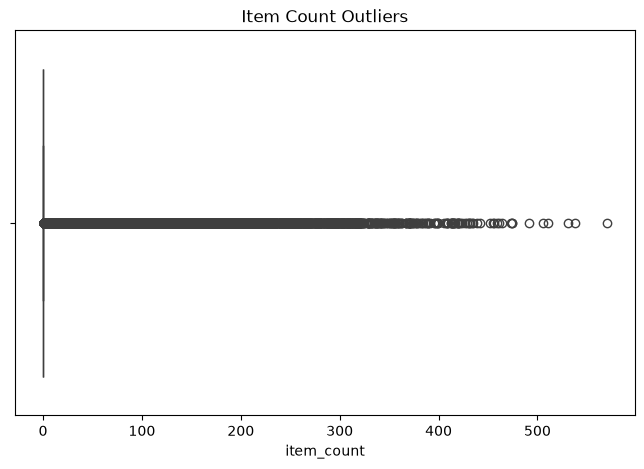

In [100]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=sales["item_count"])
plt.title("Item Count Outliers")
plt.show()

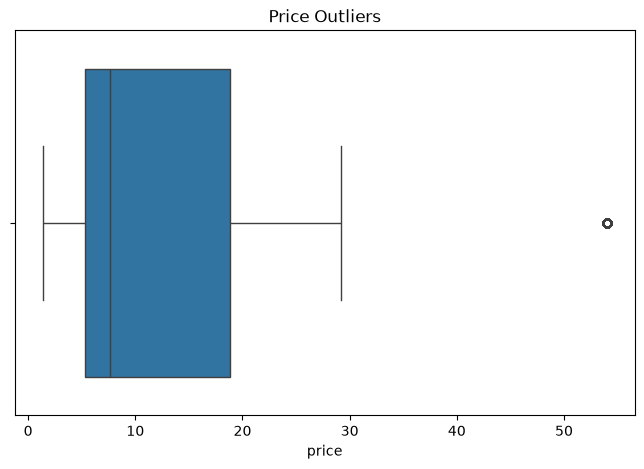

In [101]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=sales["price"])
plt.title("Price Outliers")
plt.show()

In [102]:
sales["date"] = pd.to_datetime(sales["date"])

print(sales["date"].min())
print(sales["date"].max())

2019-01-01 00:00:00
2021-12-31 00:00:00


In [103]:
merged_data = sales.merge(
    items,
    left_on="item_id",
    right_on="id",
    how="left",
    suffixes=("", "_item")
)

display(merged_data.head())
print(merged_data.shape)

,date,item_id,price,item_count,id,store_id,name,kcal,cost
0,2019-01-01,3,29.22,2.0,3,1,Sweet Fruity Cake,931,29.22
1,2019-01-01,4,26.42,22.0,4,1,Amazing Steak Dinner with Rolls,763,26.42
2,2019-01-01,12,4.87,7.0,12,1,Fantastic Sweet Cola,478,4.87
3,2019-01-01,13,4.18,12.0,13,1,Sweet Frozen Soft Drink,490,4.18
4,2019-01-01,16,3.21,136.0,16,1,Frozen Milky Smoothy,284,3.21


(109600, 9)


In [104]:
merged_data = merged_data.merge(
    restaurants,
    left_on="store_id",
    right_on="id",
    how="left",
    suffixes=("", "_restaurant")
)

display(merged_data.head())
print(merged_data.shape)

,date,item_id,price,item_count,id,store_id,name,kcal,cost,id_restaurant,name_restaurant
0,2019-01-01,3,29.22,2.0,3,1,Sweet Fruity Cake,931,29.22,1,Bob's Diner
1,2019-01-01,4,26.42,22.0,4,1,Amazing Steak Dinner with Rolls,763,26.42,1,Bob's Diner
2,2019-01-01,12,4.87,7.0,12,1,Fantastic Sweet Cola,478,4.87,1,Bob's Diner
3,2019-01-01,13,4.18,12.0,13,1,Sweet Frozen Soft Drink,490,4.18,1,Bob's Diner
4,2019-01-01,16,3.21,136.0,16,1,Frozen Milky Smoothy,284,3.21,1,Bob's Diner


(109600, 11)


In [105]:
merged_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 109600 entries, 0 to 109599
Data columns (total 11 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   date             109600 non-null  datetime64[us]
 1   item_id          109600 non-null  int64         
 2   price            109600 non-null  float64       
 3   item_count       109600 non-null  float64       
 4   id               109600 non-null  int64         
 5   store_id         109600 non-null  int64         
 6   name             109600 non-null  str           
 7   kcal             109600 non-null  int64         
 8   cost             109600 non-null  float64       
 9   id_restaurant    109600 non-null  int64         
 10  name_restaurant  109600 non-null  str           
dtypes: datetime64[us](1), float64(3), int64(5), str(2)
memory usage: 9.2 MB


In [106]:
print("Missing values after merge:")
print(merged_data.isnull().sum())

Missing values after merge:
date               0
item_id            0
price              0
item_count         0
id                 0
store_id           0
name               0
kcal               0
cost               0
id_restaurant      0
name_restaurant    0
dtype: int64


In [107]:
print("Rows:", len(merged_data))
print("Columns:", len(merged_data.columns))

Rows: 109600
Columns: 11


In [108]:
merged_data = merged_data[
    [
        "date",
        "item_id",
        "price",
        "item_count",
        "name",
        "kcal",
        "store_id",
        "name_restaurant"
    ]
]

In [109]:
merged_data = merged_data.rename(
    columns={
        "name": "item_name",
        "name_restaurant": "store_name"
    }
)

In [110]:
print("Missing values:")
print(merged_data.isnull().sum())

Missing values:
date          0
item_id       0
price         0
item_count    0
item_name     0
kcal          0
store_id      0
store_name    0
dtype: int64


In [111]:
print("Duplicate rows:", merged_data.duplicated().sum())

Duplicate rows: 0


In [112]:
display(merged_data.head(10))

,date,item_id,price,item_count,item_name,kcal,store_id,store_name
0,2019-01-01,3,29.22,2.0,Sweet Fruity Cake,931,1,Bob's Diner
1,2019-01-01,4,26.42,22.0,Amazing Steak Dinner with Rolls,763,1,Bob's Diner
2,2019-01-01,12,4.87,7.0,Fantastic Sweet Cola,478,1,Bob's Diner
3,2019-01-01,13,4.18,12.0,Sweet Frozen Soft Drink,490,1,Bob's Diner
4,2019-01-01,16,3.21,136.0,Frozen Milky Smoothy,284,1,Bob's Diner
5,2019-01-01,19,2.89,108.0,Strawberry Smoothy,145,1,Bob's Diner
6,2019-01-01,21,23.23,13.0,Amazing Fish with Vegetables Meal,269,1,Bob's Diner
7,2019-01-01,23,10.86,10.0,Awesome Sweet Lamb Cake,671,1,Bob's Diner
8,2019-01-01,27,26.21,1.0,Steak Meal,607,6,Surfs Up
9,2019-01-01,35,4.36,1.0,Blue Ribbon Cocktail,456,6,Surfs Up


DATASET SHAPES
Restaurants: (6, 2)
Sales: (109600, 4)
Items: (100, 5)

RESTAURANTS - FIRST 5 ROWS


,id,name
0,1,Bob's Diner
1,2,Beachfront Bar
2,3,Sweet Shack
3,4,Fou Cher
4,5,Corner Cafe



SALES - FIRST 5 ROWS


,date,item_id,price,item_count
0,2019-01-01,3,29.22,2.0
1,2019-01-01,4,26.42,22.0
2,2019-01-01,12,4.87,7.0
3,2019-01-01,13,4.18,12.0
4,2019-01-01,16,3.21,136.0



ITEMS - FIRST 5 ROWS


,id,store_id,name,kcal,cost
0,1,4,Chocolate Cake,554,6.71
1,2,4,Breaded Fish with Vegetables Meal,772,15.09
2,3,1,Sweet Fruity Cake,931,29.22
3,4,1,Amazing Steak Dinner with Rolls,763,26.42
4,5,5,Milk Cake,583,6.07



RESTAURANTS STRUCTURE
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      6 non-null      int64
 1   name    6 non-null      str  
dtypes: int64(1), str(1)
memory usage: 228.0 bytes

SALES STRUCTURE
<class 'pandas.DataFrame'>
RangeIndex: 109600 entries, 0 to 109599
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   date        109600 non-null  str    
 1   item_id     109600 non-null  int64  
 2   price       109600 non-null  float64
 3   item_count  109600 non-null  float64
dtypes: float64(2), int64(1), str(1)
memory usage: 3.3 MB

ITEMS STRUCTURE
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        100 non-null    int64  
 1   store_id  100 non-null    int64  
 2   n

,date,item_id,price,item_count
count,109600,109600.000000,109600.000000,109600.000000
mean,2020-07-01 12:00:00,50.500000,11.763700,6.339297
min,2019-01-01 00:00:00,1.000000,1.390000,0.000000
25%,2019-10-01 18:00:00,25.750000,5.280000,0.000000
50%,2020-07-01 12:00:00,50.500000,7.625000,0.000000
75%,2021-04-01 06:00:00,75.250000,18.790000,0.000000
max,2021-12-31 00:00:00,100.000000,53.980000,570.000000
std,NaN,28.866202,8.946225,30.003728



ITEMS DESCRIPTIVE STATISTICS


,id,store_id,kcal,cost
count,100.000000,100.000000,100.000000,100.000000
mean,50.500000,3.520000,536.730000,11.763700
std,29.011492,1.708446,202.212852,8.991254
min,1.000000,1.000000,78.000000,1.390000
25%,25.750000,2.000000,406.250000,5.280000
50%,50.500000,4.000000,572.500000,7.625000
75%,75.250000,5.000000,638.250000,18.790000
max,100.000000,6.000000,1023.000000,53.980000


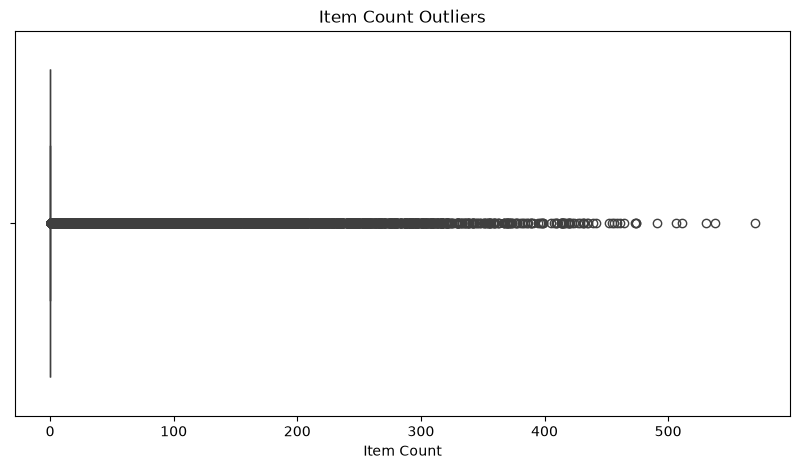

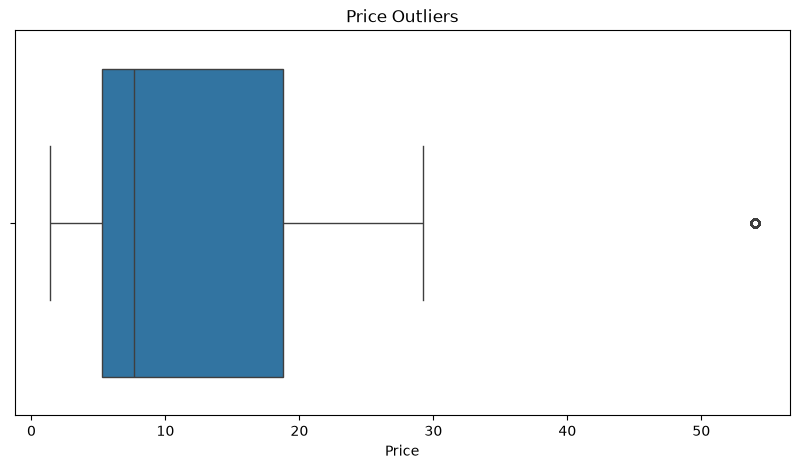


OUTLIER SUMMARY

Item Count:
Lower bound: 0.0
Upper bound: 0.0
Number of outliers: 23484

Price:
Lower bound: -14.984999999999996
Upper bound: 39.05499999999999
Number of outliers: 1096

SAMPLE ITEM COUNT OUTLIERS


,date,item_id,price,item_count
0,2019-01-01,3,29.22,2.0
1,2019-01-01,4,26.42,22.0
2,2019-01-01,12,4.87,7.0
3,2019-01-01,13,4.18,12.0
4,2019-01-01,16,3.21,136.0
5,2019-01-01,19,2.89,108.0
6,2019-01-01,21,23.23,13.0
7,2019-01-01,23,10.86,10.0
8,2019-01-01,27,26.21,1.0
9,2019-01-01,35,4.36,1.0



SAMPLE PRICE OUTLIERS


,date,item_id,price,item_count
82,2019-01-01,80,53.98,0.0
115,2019-01-02,80,53.98,2.0
216,2019-01-03,80,53.98,2.0
316,2019-01-04,80,53.98,1.0
482,2019-01-05,80,53.98,0.0
580,2019-01-06,80,53.98,0.0
683,2019-01-07,80,53.98,0.0
715,2019-01-08,80,53.98,1.0
881,2019-01-09,80,53.98,0.0
982,2019-01-10,80,53.98,0.0



MERGED DATASET
Shape: (109600, 8)


,date,item_id,price,item_count,item_name,kcal,store_id,store_name
0,2019-01-01,3,29.22,2.0,Sweet Fruity Cake,931,1,Bob's Diner
1,2019-01-01,4,26.42,22.0,Amazing Steak Dinner with Rolls,763,1,Bob's Diner
2,2019-01-01,12,4.87,7.0,Fantastic Sweet Cola,478,1,Bob's Diner
3,2019-01-01,13,4.18,12.0,Sweet Frozen Soft Drink,490,1,Bob's Diner
4,2019-01-01,16,3.21,136.0,Frozen Milky Smoothy,284,1,Bob's Diner
5,2019-01-01,19,2.89,108.0,Strawberry Smoothy,145,1,Bob's Diner
6,2019-01-01,21,23.23,13.0,Amazing Fish with Vegetables Meal,269,1,Bob's Diner
7,2019-01-01,23,10.86,10.0,Awesome Sweet Lamb Cake,671,1,Bob's Diner
8,2019-01-01,27,26.21,1.0,Steak Meal,607,6,Surfs Up
9,2019-01-01,35,4.36,1.0,Blue Ribbon Cocktail,456,6,Surfs Up



MERGED DATASET STRUCTURE
<class 'pandas.DataFrame'>
RangeIndex: 109600 entries, 0 to 109599
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   date        109600 non-null  datetime64[us]
 1   item_id     109600 non-null  int64         
 2   price       109600 non-null  float64       
 3   item_count  109600 non-null  float64       
 4   item_name   109600 non-null  str           
 5   kcal        109600 non-null  int64         
 6   store_id    109600 non-null  int64         
 7   store_name  109600 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(3), str(2)
memory usage: 6.7 MB

MISSING VALUES AFTER MERGE
date          0
item_id       0
price         0
item_count    0
item_name     0
kcal          0
store_id      0
store_name    0
dtype: int64

DUPLICATES AFTER MERGE
Duplicate rows: 0

MERGED DATASET SUMMARY
Number of stores: 6
Number of items: 100
Number of item names: 94
Number 

In [113]:
# ============================================================
# SALES FORECASTING - PHASE 1
# PRELIMINARY ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# 2. LOAD DATASETS
# ------------------------------------------------------------

restaurants = pd.read_csv("../data/restaurants.csv")
sales = pd.read_csv("../data/sales.csv")
items = pd.read_csv("../data/items.csv")


# ------------------------------------------------------------
# 3. BASIC DATASET INSPECTION
# ------------------------------------------------------------

print("=" * 60)
print("DATASET SHAPES")
print("=" * 60)

print("Restaurants:", restaurants.shape)
print("Sales:", sales.shape)
print("Items:", items.shape)


# ------------------------------------------------------------
# 4. DISPLAY FIRST FEW ROWS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("RESTAURANTS - FIRST 5 ROWS")
print("=" * 60)

display(restaurants.head())


print("\n" + "=" * 60)
print("SALES - FIRST 5 ROWS")
print("=" * 60)

display(sales.head())


print("\n" + "=" * 60)
print("ITEMS - FIRST 5 ROWS")
print("=" * 60)

display(items.head())


# ------------------------------------------------------------
# 5. DATASET STRUCTURE
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("RESTAURANTS STRUCTURE")
print("=" * 60)

restaurants.info()


print("\n" + "=" * 60)
print("SALES STRUCTURE")
print("=" * 60)

sales.info()


print("\n" + "=" * 60)
print("ITEMS STRUCTURE")
print("=" * 60)

items.info()


# ------------------------------------------------------------
# 6. CHECK MISSING VALUES
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MISSING VALUES")
print("=" * 60)

print("\nRestaurants:")
print(restaurants.isnull().sum())

print("\nSales:")
print(sales.isnull().sum())

print("\nItems:")
print(items.isnull().sum())


# ------------------------------------------------------------
# 7. CHECK DUPLICATES
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DUPLICATE RECORDS")
print("=" * 60)

print("Restaurant duplicates:", restaurants.duplicated().sum())
print("Sales duplicates:", sales.duplicated().sum())
print("Item duplicates:", items.duplicated().sum())


# ------------------------------------------------------------
# 8. CONVERT SALES DATE TO DATETIME
# ------------------------------------------------------------

sales["date"] = pd.to_datetime(sales["date"])

print("\n" + "=" * 60)
print("SALES DATE RANGE")
print("=" * 60)

print("Start date:", sales["date"].min())
print("End date:", sales["date"].max())


# ------------------------------------------------------------
# 9. DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SALES DESCRIPTIVE STATISTICS")
print("=" * 60)

display(sales.describe())


print("\n" + "=" * 60)
print("ITEMS DESCRIPTIVE STATISTICS")
print("=" * 60)

display(items.describe())


# ------------------------------------------------------------
# 10. OUTLIER INSPECTION - ITEM COUNT
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.boxplot(x=sales["item_count"])

plt.title("Item Count Outliers")
plt.xlabel("Item Count")

plt.show()


# ------------------------------------------------------------
# 11. OUTLIER INSPECTION - PRICE
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.boxplot(x=sales["price"])

plt.title("Price Outliers")
plt.xlabel("Price")

plt.show()


# ------------------------------------------------------------
# 12. IDENTIFY OUTLIERS USING IQR
# ------------------------------------------------------------

def find_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return outliers, lower_bound, upper_bound


item_count_outliers, item_count_lower, item_count_upper = \
    find_outliers_iqr(sales, "item_count")

price_outliers, price_lower, price_upper = \
    find_outliers_iqr(sales, "price")


print("\n" + "=" * 60)
print("OUTLIER SUMMARY")
print("=" * 60)

print("\nItem Count:")
print("Lower bound:", item_count_lower)
print("Upper bound:", item_count_upper)
print("Number of outliers:", len(item_count_outliers))

print("\nPrice:")
print("Lower bound:", price_lower)
print("Upper bound:", price_upper)
print("Number of outliers:", len(price_outliers))


# ------------------------------------------------------------
# 13. DISPLAY SOME OUTLIER RECORDS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SAMPLE ITEM COUNT OUTLIERS")
print("=" * 60)

display(item_count_outliers.head(10))


print("\n" + "=" * 60)
print("SAMPLE PRICE OUTLIERS")
print("=" * 60)

display(price_outliers.head(10))


# ------------------------------------------------------------
# 14. MERGE SALES WITH ITEMS
# ------------------------------------------------------------

merged_data = sales.merge(
    items,
    left_on="item_id",
    right_on="id",
    how="left",
    suffixes=("", "_item")
)


# ------------------------------------------------------------
# 15. MERGE WITH RESTAURANTS
# ------------------------------------------------------------

merged_data = merged_data.merge(
    restaurants,
    left_on="store_id",
    right_on="id",
    how="left",
    suffixes=("", "_restaurant")
)


# ------------------------------------------------------------
# 16. SELECT REQUIRED COLUMNS
# ------------------------------------------------------------

merged_data = merged_data[
    [
        "date",
        "item_id",
        "price",
        "item_count",
        "name",
        "kcal",
        "store_id",
        "name_restaurant"
    ]
]


# ------------------------------------------------------------
# 17. RENAME COLUMNS
# ------------------------------------------------------------

merged_data = merged_data.rename(
    columns={
        "name": "item_name",
        "name_restaurant": "store_name"
    }
)


# ------------------------------------------------------------
# 18. CHECK FINAL MERGED DATASET
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MERGED DATASET")
print("=" * 60)

print("Shape:", merged_data.shape)

display(merged_data.head(10))


# ------------------------------------------------------------
# 19. FINAL STRUCTURE
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MERGED DATASET STRUCTURE")
print("=" * 60)

merged_data.info()


# ------------------------------------------------------------
# 20. CHECK MISSING VALUES AFTER MERGE
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MISSING VALUES AFTER MERGE")
print("=" * 60)

print(merged_data.isnull().sum())


# ------------------------------------------------------------
# 21. CHECK DUPLICATES AFTER MERGE
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DUPLICATES AFTER MERGE")
print("=" * 60)

print("Duplicate rows:", merged_data.duplicated().sum())


# ------------------------------------------------------------
# 22. VERIFY UNIQUE STORES AND ITEMS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MERGED DATASET SUMMARY")
print("=" * 60)

print("Number of stores:", merged_data["store_id"].nunique())
print("Number of items:", merged_data["item_id"].nunique())
print("Number of item names:", merged_data["item_name"].nunique())
print("Number of restaurants:", merged_data["store_name"].nunique())


# ------------------------------------------------------------
# 23. FINAL COLUMN LIST
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL COLUMNS")
print("=" * 60)

print(merged_data.columns.tolist())


# ------------------------------------------------------------
# 24. SAVE MERGED DATASET
# ------------------------------------------------------------

merged_data.to_csv(
    "../data/merged_sales_data.csv",
    index=False
)

print("\nMerged dataset saved successfully.")

In [114]:
# ============================================================
# PHASE 2 - EXPLORATORY DATA ANALYSIS
# CELL 1 - PREPARE DATA
# ============================================================

# Work on a copy so the original merged dataset remains unchanged
eda_data = merged_data.copy()

# Ensure date is datetime
eda_data["date"] = pd.to_datetime(eda_data["date"])

# Create basic time features required for analysis
eda_data["year"] = eda_data["date"].dt.year
eda_data["month"] = eda_data["date"].dt.month
eda_data["month_name"] = eda_data["date"].dt.month_name()
eda_data["quarter"] = eda_data["date"].dt.quarter
eda_data["day_of_week"] = eda_data["date"].dt.day_name()
eda_data["day_of_week_num"] = eda_data["date"].dt.dayofweek

# Calculate revenue
eda_data["revenue"] = eda_data["price"] * eda_data["item_count"]

print("EDA dataset shape:", eda_data.shape)
display(eda_data.head())

EDA dataset shape: (109600, 15)


,date,item_id,price,item_count,item_name,kcal,store_id,store_name,year,month,month_name,quarter,day_of_week,day_of_week_num,revenue
0,2019-01-01,3,29.22,2.0,Sweet Fruity Cake,931,1,Bob's Diner,2019,1,January,1,Tuesday,1,58.44
1,2019-01-01,4,26.42,22.0,Amazing Steak Dinner with Rolls,763,1,Bob's Diner,2019,1,January,1,Tuesday,1,581.24
2,2019-01-01,12,4.87,7.0,Fantastic Sweet Cola,478,1,Bob's Diner,2019,1,January,1,Tuesday,1,34.09
3,2019-01-01,13,4.18,12.0,Sweet Frozen Soft Drink,490,1,Bob's Diner,2019,1,January,1,Tuesday,1,50.16
4,2019-01-01,16,3.21,136.0,Frozen Milky Smoothy,284,1,Bob's Diner,2019,1,January,1,Tuesday,1,436.56


In [115]:
# ============================================================
# EDA (a) - OVERALL SALES
# CELL 2 - SALES SUMMARY
# ============================================================

daily_sales = (
    eda_data
    .groupby("date", as_index=False)["item_count"]
    .sum()
)

daily_sales = daily_sales.sort_values("date")

print("Total items sold:", eda_data["item_count"].sum())
print("Average items sold per day:", eda_data["item_count"].sum() / eda_data["date"].nunique())
print("Maximum items sold in a day:", daily_sales["item_count"].max())
print("Minimum items sold in a day:", daily_sales["item_count"].min())

display(daily_sales.head())

Total items sold: 694787.0
Average items sold per day: 633.9297445255474
Maximum items sold in a day: 1201.0
Minimum items sold in a day: 175.0


,date,item_count
0,2019-01-01,427.0
1,2019-01-02,337.0
2,2019-01-03,445.0
3,2019-01-04,564.0
4,2019-01-05,552.0


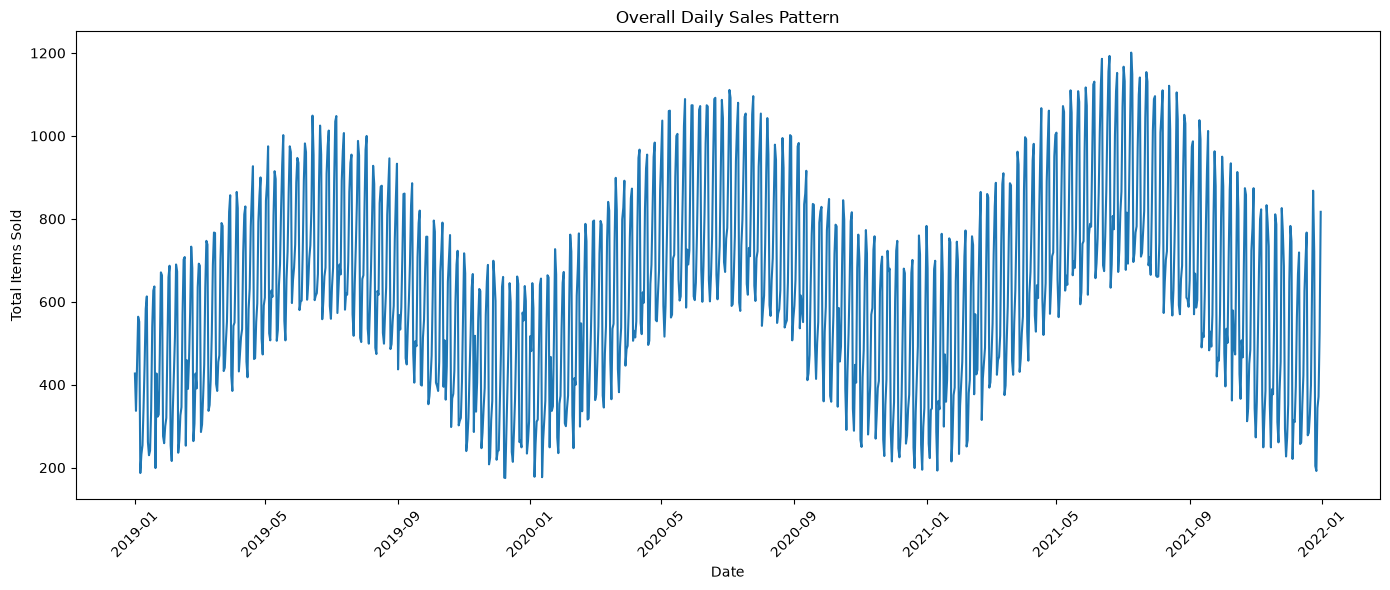

In [116]:
# ============================================================
# EDA (a) - OVERALL SALES
# CELL 3 - SALES TREND
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["item_count"]
)

plt.title("Overall Daily Sales Pattern")
plt.xlabel("Date")
plt.ylabel("Total Items Sold")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

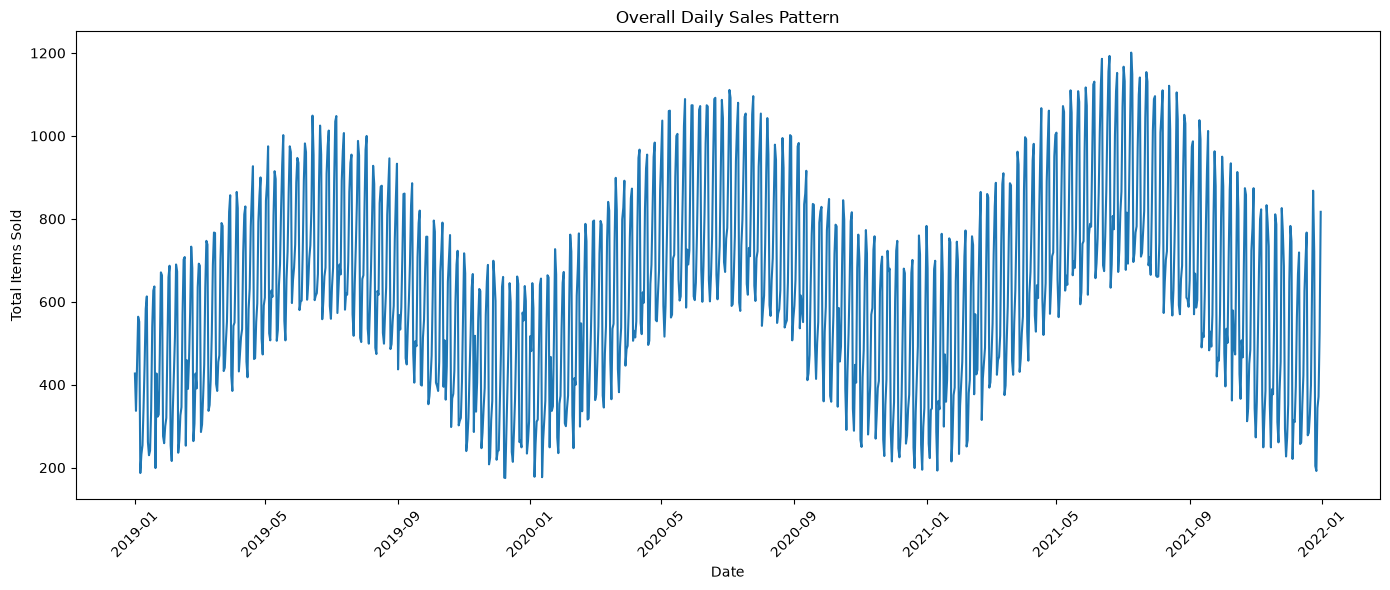

In [117]:
# ============================================================
# EDA (a) - OVERALL SALES
# CELL 3 - SALES TREND
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["item_count"]
)

plt.title("Overall Daily Sales Pattern")
plt.xlabel("Date")
plt.ylabel("Total Items Sold")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [118]:
# ============================================================
# EDA (b) - SALES BY DAY OF WEEK
# CELL 4
# ============================================================

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_sales = (
    eda_data
    .groupby(["day_of_week_num", "day_of_week"])["item_count"]
    .sum()
    .reset_index()
    .sort_values("day_of_week_num")
)

display(
    weekday_sales[
        ["day_of_week", "item_count"]
    ]
)

,day_of_week,item_count
0,Monday,70112.0
1,Tuesday,79454.0
2,Wednesday,88298.0
3,Thursday,116947.0
4,Friday,136300.0
5,Saturday,135644.0
6,Sunday,68032.0


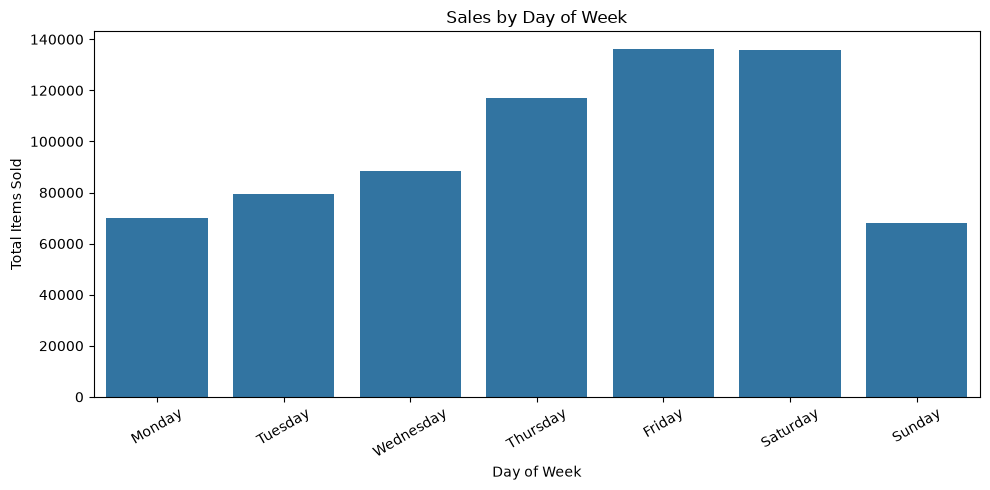

In [119]:
# ============================================================
# EDA (b) - SALES BY DAY OF WEEK
# CELL 5 - VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_sales,
    x="day_of_week",
    y="item_count",
    order=weekday_order
)

plt.title("Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Total Items Sold")
plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

In [120]:
# ============================================================
# EDA (c) - MONTHLY SALES
# CELL 6
# ============================================================

month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

monthly_sales = (
    eda_data
    .groupby("month")["item_count"]
    .sum()
    .reset_index()
    .sort_values("month")
)

monthly_sales["month_name"] = monthly_sales["month"].apply(
    lambda x: month_order[x - 1]
)

display(monthly_sales)

,month,item_count,month_name
0,1,41270.0,January
1,2,43596.0,February
2,3,55137.0,March
3,4,63145.0,April
4,5,73632.0,May
5,6,74423.0,June
6,7,77125.0,July
7,8,69502.0,August
8,9,58660.0,September
9,10,53403.0,October


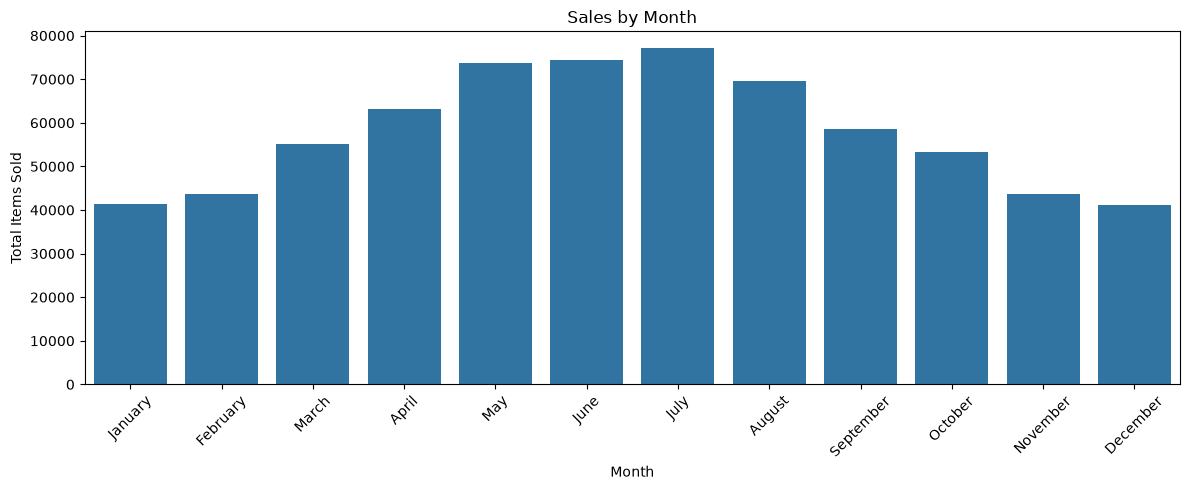

In [121]:
# ============================================================
# EDA (c) - MONTHLY SALES
# CELL 7 - VISUALIZATION
# ============================================================

plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_sales,
    x="month_name",
    y="item_count",
    order=month_order
)

plt.title("Sales by Month")
plt.xlabel("Month")
plt.ylabel("Total Items Sold")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [122]:
# ============================================================
# EDA (d) - QUARTERLY SALES
# CELL 8
# ============================================================

yearly_quarter_sales = (
    eda_data
    .groupby(["year", "quarter"])["item_count"]
    .sum()
    .reset_index()
)

quarterly_average = (
    yearly_quarter_sales
    .groupby("quarter")["item_count"]
    .mean()
    .reset_index()
)

quarterly_average["quarter_name"] = (
    "Q" + quarterly_average["quarter"].astype(str)
)

display(yearly_quarter_sales)
display(quarterly_average)

,year,quarter,item_count
0,2019,1,43231.0
1,2019,2,65259.0
2,2019,3,63152.0
3,2019,4,42595.0
4,2020,1,47278.0
5,2020,2,70654.0
6,2020,3,68241.0
7,2020,4,46408.0
8,2021,1,49494.0
9,2021,2,75287.0


,quarter,item_count,quarter_name
0,1,46667.666667,Q1
1,2,70400.000000,Q2
2,3,68429.000000,Q3
3,4,46099.000000,Q4


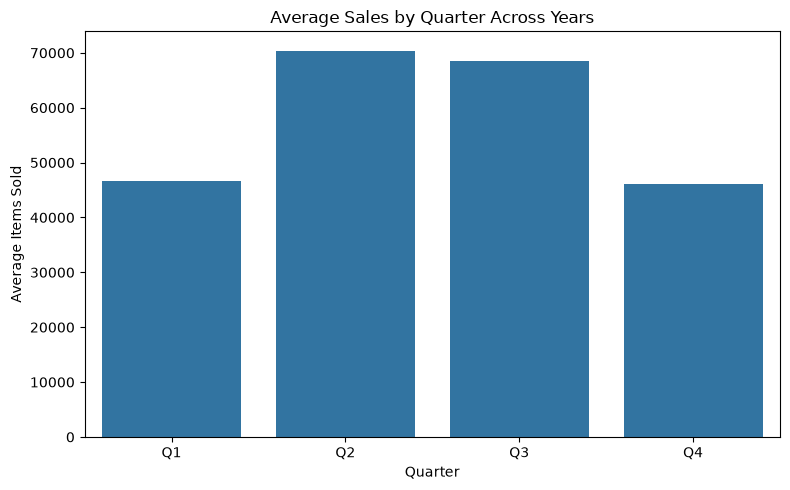

In [123]:
# ============================================================
# EDA (d) - QUARTERLY SALES
# CELL 9 - VISUALIZATION
# ============================================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=quarterly_average,
    x="quarter_name",
    y="item_count"
)

plt.title("Average Sales by Quarter Across Years")
plt.xlabel("Quarter")
plt.ylabel("Average Items Sold")
plt.tight_layout()

plt.show()

In [124]:
# ============================================================
# EDA (e) - RESTAURANT PERFORMANCE
# CELL 10 - OVERALL PERFORMANCE
# ============================================================

restaurant_sales = (
    eda_data
    .groupby("store_name")["item_count"]
    .sum()
    .reset_index()
    .sort_values("item_count", ascending=False)
)

display(restaurant_sales)

highest_sales_restaurant = restaurant_sales.iloc[0]

print(
    "Restaurant with the highest sales:",
    highest_sales_restaurant["store_name"]
)

print(
    "Total items sold:",
    highest_sales_restaurant["item_count"]
)

,store_name,item_count
1,Bob's Diner,687527.0
4,Surfs Up,1803.0
5,Sweet Shack,1736.0
2,Corner Cafe,1310.0
0,Beachfront Bar,1305.0
3,Fou Cher,1106.0


Restaurant with the highest sales: Bob's Diner
Total items sold: 687527.0


In [125]:
# ============================================================
# EDA (e) - RESTAURANT PERFORMANCE
# CELL 11 - YEARLY PERFORMANCE
# ============================================================

restaurant_yearly_sales = (
    eda_data
    .groupby(["year", "store_name"])["item_count"]
    .sum()
    .reset_index()
)

display(restaurant_yearly_sales)

,year,store_name,item_count
0,2019,Beachfront Bar,439.0
1,2019,Bob's Diner,211799.0
2,2019,Corner Cafe,423.0
3,2019,Fou Cher,392.0
4,2019,Surfs Up,594.0
5,2019,Sweet Shack,590.0
6,2020,Beachfront Bar,437.0
7,2020,Bob's Diner,230191.0
8,2020,Corner Cafe,415.0
9,2020,Fou Cher,357.0


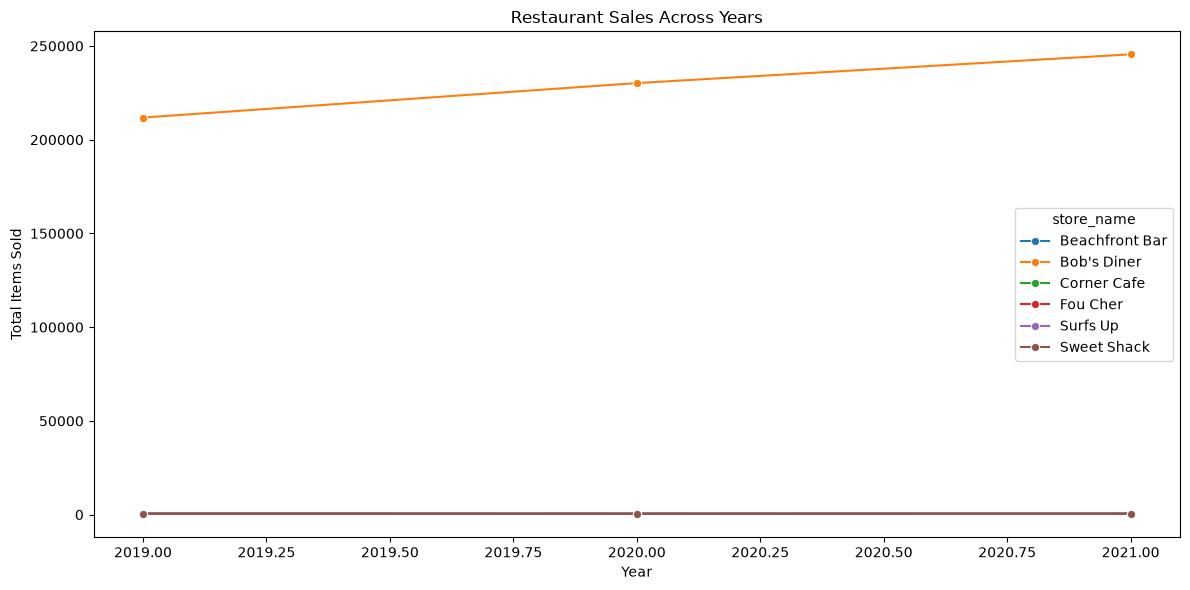

In [126]:
# ============================================================
# EDA (e) - RESTAURANT PERFORMANCE
# CELL 12 - YEARLY VISUALIZATION
# ============================================================

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=restaurant_yearly_sales,
    x="year",
    y="item_count",
    hue="store_name",
    marker="o"
)

plt.title("Restaurant Sales Across Years")
plt.xlabel("Year")
plt.ylabel("Total Items Sold")
plt.tight_layout()

plt.show()

In [127]:
# ============================================================
# EDA (e) - RESTAURANT PERFORMANCE
# CELL 13 - MONTHLY PERFORMANCE
# ============================================================

restaurant_monthly_sales = (
    eda_data
    .groupby(["month", "store_name"])["item_count"]
    .sum()
    .reset_index()
)

display(restaurant_monthly_sales.head(20))

,month,store_name,item_count
0,1,Beachfront Bar,107.0
1,1,Bob's Diner,40672.0
2,1,Corner Cafe,82.0
3,1,Fou Cher,109.0
4,1,Surfs Up,132.0
5,1,Sweet Shack,168.0
6,2,Beachfront Bar,109.0
7,2,Bob's Diner,43006.0
8,2,Corner Cafe,111.0
9,2,Fou Cher,72.0


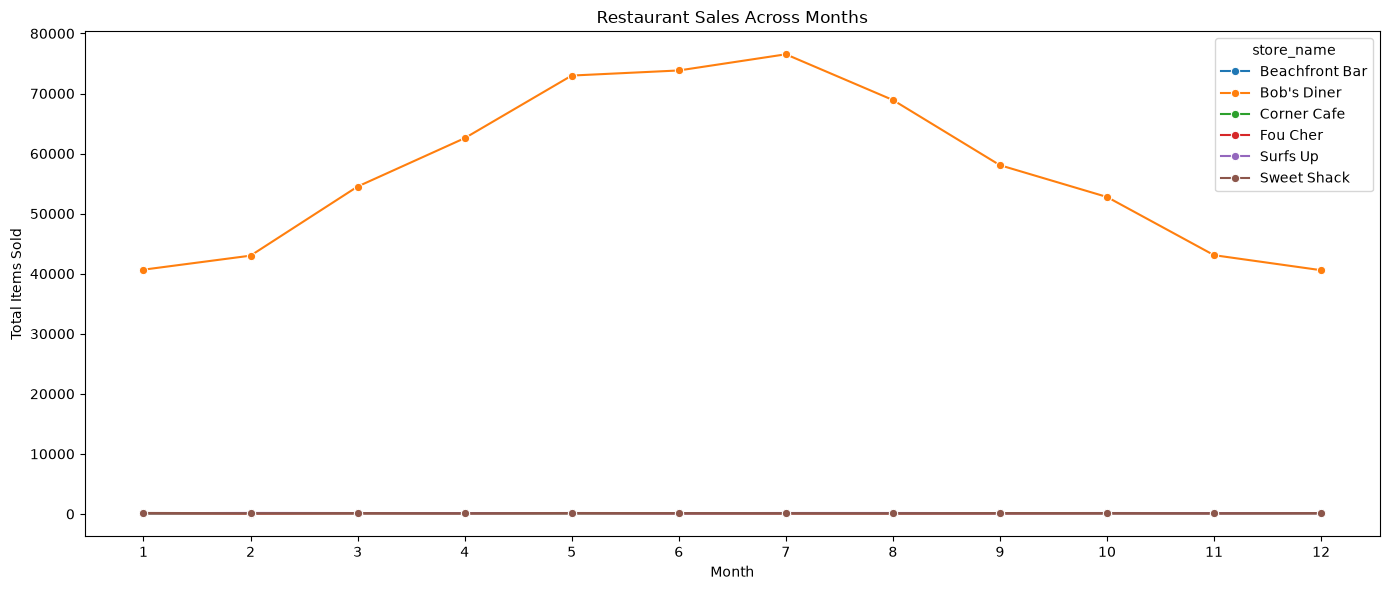

In [128]:
# ============================================================
# EDA (e) - RESTAURANT PERFORMANCE
# CELL 14 - MONTHLY VISUALIZATION
# ============================================================

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=restaurant_monthly_sales,
    x="month",
    y="item_count",
    hue="store_name",
    marker="o"
)

plt.title("Restaurant Sales Across Months")
plt.xlabel("Month")
plt.ylabel("Total Items Sold")
plt.xticks(range(1, 13))
plt.tight_layout()

plt.show()

In [129]:
# ============================================================
# EDA (e) - RESTAURANT PERFORMANCE
# CELL 15 - DAY-OF-WEEK PERFORMANCE
# ============================================================

restaurant_weekday_sales = (
    eda_data
    .groupby(
        ["day_of_week_num", "day_of_week", "store_name"]
    )["item_count"]
    .sum()
    .reset_index()
    .sort_values("day_of_week_num")
)

display(restaurant_weekday_sales.head(20))

,day_of_week_num,day_of_week,store_name,item_count
0,0,Monday,Beachfront Bar,188.0
1,0,Monday,Bob's Diner,69086.0
2,0,Monday,Corner Cafe,183.0
3,0,Monday,Fou Cher,155.0
4,0,Monday,Surfs Up,256.0
5,0,Monday,Sweet Shack,244.0
6,1,Tuesday,Beachfront Bar,188.0
7,1,Tuesday,Bob's Diner,78405.0
8,1,Tuesday,Corner Cafe,199.0
9,1,Tuesday,Fou Cher,143.0


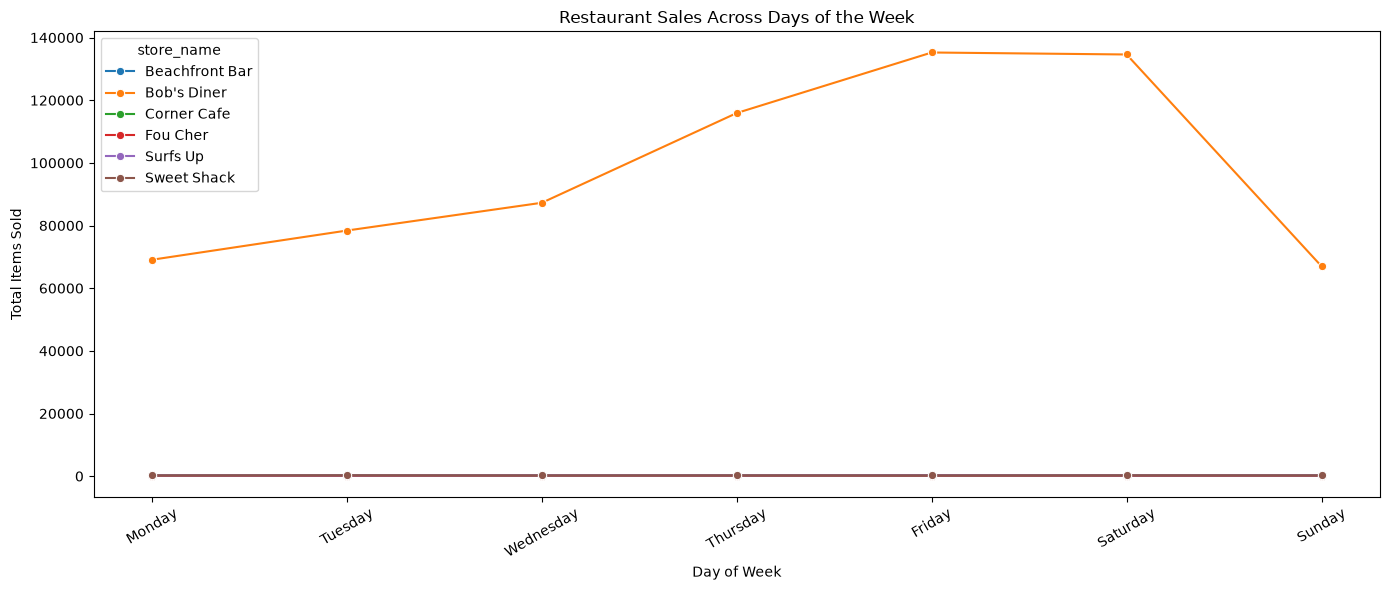

In [130]:
# ============================================================
# EDA (e) - RESTAURANT PERFORMANCE
# CELL 16 - WEEKDAY VISUALIZATION
# ============================================================

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=restaurant_weekday_sales,
    x="day_of_week_num",
    y="item_count",
    hue="store_name",
    marker="o"
)

plt.title("Restaurant Sales Across Days of the Week")
plt.xlabel("Day of Week")
plt.ylabel("Total Items Sold")

plt.xticks(
    range(7),
    weekday_order
)

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

In [131]:
# ============================================================
# EDA (f) - POPULAR ITEMS
# CELL 17 - OVERALL POPULAR ITEMS
# ============================================================

popular_items = (
    eda_data
    .groupby("item_name")["item_count"]
    .sum()
    .reset_index()
    .sort_values("item_count", ascending=False)
)

display(popular_items.head(10))

,item_name,item_count
85,Strawberry Smoothy,236337.0
46,Frozen Milky Smoothy,103263.0
9,Amazing pork lunch,61043.0
64,Mutton Dinner,52772.0
67,Orange Juice,43874.0
22,Blue Ribbon Beef Entree,42774.0
4,Amazing Steak Dinner with Rolls,34439.0
88,Sweet Frozen Soft Drink,27490.0
83,Sea Bass with Vegetables Dinner,23839.0
90,Sweet Lamb Cake,18764.0


In [132]:
# ============================================================
# EDA (f) - POPULAR ITEMS
# CELL 18 - STORES SELLING POPULAR ITEMS
# ============================================================

top_items = popular_items.head(10)["item_name"]

popular_items_stores = (
    eda_data[
        eda_data["item_name"].isin(top_items)
    ][
        ["item_name", "store_name"]
    ]
    .drop_duplicates()
    .sort_values(["item_name", "store_name"])
)

display(popular_items_stores)

,item_name,store_name
1,Amazing Steak Dinner with Rolls,Bob's Diner
17,Amazing pork lunch,Bob's Diner
13,Blue Ribbon Beef Entree,Bob's Diner
4,Frozen Milky Smoothy,Bob's Diner
76,Frozen Milky Smoothy,Corner Cafe
48,Mutton Dinner,Bob's Diner
27,Orange Juice,Bob's Diner
12,Sea Bass with Vegetables Dinner,Bob's Diner
5,Strawberry Smoothy,Bob's Diner
3,Sweet Frozen Soft Drink,Bob's Diner


In [133]:
# ============================================================
# EDA (f) - POPULAR ITEMS
# CELL 19 - MOST POPULAR ITEM PER STORE
# ============================================================

store_item_sales = (
    eda_data
    .groupby(["store_name", "item_name"])["item_count"]
    .sum()
    .reset_index()
)

most_popular_per_store = (
    store_item_sales
    .sort_values(
        ["store_name", "item_count"],
        ascending=[True, False]
    )
    .groupby("store_name")
    .head(1)
    .reset_index(drop=True)
)

display(most_popular_per_store)

,store_name,item_name,item_count
0,Beachfront Bar,Fantastic Milky Smoothy,1147.0
1,Bob's Diner,Strawberry Smoothy,236337.0
2,Corner Cafe,Frozen Milky Smoothy,273.0
3,Fou Cher,Blue Ribbon Fruity Vegi Lunch,298.0
4,Surfs Up,Awesome Soft Drink,997.0
5,Sweet Shack,Awesome Smoothy,1692.0


In [134]:
# ============================================================
# EDA (g) - SALES VOLUME VS MONEY
# CELL 20
# ============================================================

restaurant_volume = (
    eda_data
    .groupby("store_name")["item_count"]
    .sum()
    .reset_index()
    .rename(columns={"item_count": "total_items_sold"})
)

restaurant_daily_revenue = (
    eda_data
    .groupby(["store_name", "date"])["revenue"]
    .sum()
    .reset_index()
)

average_daily_revenue = (
    restaurant_daily_revenue
    .groupby("store_name")["revenue"]
    .mean()
    .reset_index()
    .rename(columns={"revenue": "average_daily_revenue"})
)

volume_vs_money = restaurant_volume.merge(
    average_daily_revenue,
    on="store_name"
)

volume_vs_money = volume_vs_money.sort_values(
    "total_items_sold",
    ascending=False
)

display(volume_vs_money)

,store_name,total_items_sold,average_daily_revenue
1,Bob's Diner,687527.0,5782.185849
4,Surfs Up,1803.0,14.280557
5,Sweet Shack,1736.0,2.352436
2,Corner Cafe,1310.0,15.101670
0,Beachfront Bar,1305.0,3.463686
3,Fou Cher,1106.0,25.442856


In [135]:
# ============================================================
# EDA (g) - SALES VOLUME VS MONEY
# CELL 21 - COMPARISON
# ============================================================

highest_volume_store = (
    volume_vs_money
    .sort_values("total_items_sold", ascending=False)
    .iloc[0]
)

highest_daily_money_store = (
    volume_vs_money
    .sort_values("average_daily_revenue", ascending=False)
    .iloc[0]
)

print("Highest sales volume store:")
print(highest_volume_store["store_name"])
print("Total items sold:", highest_volume_store["total_items_sold"])

print("\nHighest average daily revenue store:")
print(highest_daily_money_store["store_name"])
print(
    "Average daily revenue:",
    round(highest_daily_money_store["average_daily_revenue"], 2)
)

if (
    highest_volume_store["store_name"]
    == highest_daily_money_store["store_name"]
):
    print("\nConclusion: Yes, the same store has the highest sales volume and highest average daily revenue.")
else:
    print("\nConclusion: No, the store with the highest sales volume is different from the store with the highest average daily revenue.")

Highest sales volume store:
Bob's Diner
Total items sold: 687527.0

Highest average daily revenue store:
Bob's Diner
Average daily revenue: 5782.19

Conclusion: Yes, the same store has the highest sales volume and highest average daily revenue.


In [136]:
# ============================================================
# EDA (h) - MOST EXPENSIVE ITEM
# CELL 22
# ============================================================

most_expensive_items = (
    items
    .sort_values(
        ["store_id", "cost"],
        ascending=[True, False]
    )
    .groupby("store_id")
    .head(1)
    .copy()
)

# Add restaurant names
most_expensive_items = most_expensive_items.merge(
    restaurants,
    left_on="store_id",
    right_on="id",
    how="left"
)

most_expensive_items = most_expensive_items[
    [
        "store_id",
        "name_y",
        "name_x",
        "cost",
        "kcal"
    ]
]

most_expensive_items = most_expensive_items.rename(
    columns={
        "name_y": "store_name",
        "name_x": "item_name"
    }
)

display(most_expensive_items)

,store_id,store_name,item_name,cost,kcal
0,1,Bob's Diner,Sweet Fruity Cake,29.22,931
1,2,Beachfront Bar,Sweet Vegi Soft Drink,5.70,538
2,3,Sweet Shack,Blue Ribbon Frozen Milky Cake,7.70,636
3,4,Fou Cher,Blue Ribbon Fruity Vegi Lunch,53.98,881
4,5,Corner Cafe,Pike Lunch,26.37,653
5,6,Surfs Up,Steak Meal,26.21,607


In [137]:
# ============================================================
# PHASE 2 - EDA SUMMARY
# CELL 23
# ============================================================

print("=" * 70)
print("EXPLORATORY DATA ANALYSIS SUMMARY")
print("=" * 70)

print("\n1. Overall Sales")
print("-" * 70)
print("Total items sold:", eda_data["item_count"].sum())
print("Total revenue:", round(eda_data["revenue"].sum(), 2))
print("Number of days:", eda_data["date"].nunique())

print("\n2. Best Sales Day of Week")
print("-" * 70)
best_weekday = weekday_sales.loc[
    weekday_sales["item_count"].idxmax()
]
print(best_weekday["day_of_week"], "→", best_weekday["item_count"], "items")

print("\n3. Best Sales Month")
print("-" * 70)
best_month = monthly_sales.loc[
    monthly_sales["item_count"].idxmax()
]
print(best_month["month_name"], "→", best_month["item_count"], "items")

print("\n4. Best Quarter")
print("-" * 70)
best_quarter = quarterly_average.loc[
    quarterly_average["item_count"].idxmax()
]
print(
    best_quarter["quarter_name"],
    "→ average",
    round(best_quarter["item_count"], 2),
    "items"
)

print("\n5. Best Restaurant")
print("-" * 70)
print(
    highest_sales_restaurant["store_name"],
    "→",
    highest_sales_restaurant["item_count"],
    "items"
)

print("\n6. Most Popular Item Overall")
print("-" * 70)
print(
    popular_items.iloc[0]["item_name"],
    "→",
    popular_items.iloc[0]["item_count"],
    "items"
)

print("\n7. Highest Sales Volume Store")
print("-" * 70)
print(highest_volume_store["store_name"])

print("\n8. Highest Average Daily Revenue Store")
print("-" * 70)
print(highest_daily_money_store["store_name"])

print("\n9. Most Expensive Items by Restaurant")
print("-" * 70)
display(most_expensive_items)


EXPLORATORY DATA ANALYSIS SUMMARY

1. Overall Sales
----------------------------------------------------------------------
Total items sold: 694787.0
Total revenue: 6403738.45
Number of days: 1096

2. Best Sales Day of Week
----------------------------------------------------------------------
Friday → 136300.0 items

3. Best Sales Month
----------------------------------------------------------------------
July → 77125.0 items

4. Best Quarter
----------------------------------------------------------------------
Q2 → average 70400.0 items

5. Best Restaurant
----------------------------------------------------------------------
Bob's Diner → 687527.0 items

6. Most Popular Item Overall
----------------------------------------------------------------------
Strawberry Smoothy → 236337.0 items

7. Highest Sales Volume Store
----------------------------------------------------------------------
Bob's Diner

8. Highest Average Daily Revenue Store
------------------------------------------

,store_id,store_name,item_name,cost,kcal
0,1,Bob's Diner,Sweet Fruity Cake,29.22,931
1,2,Beachfront Bar,Sweet Vegi Soft Drink,5.70,538
2,3,Sweet Shack,Blue Ribbon Frozen Milky Cake,7.70,636
3,4,Fou Cher,Blue Ribbon Fruity Vegi Lunch,53.98,881
4,5,Corner Cafe,Pike Lunch,26.37,653
5,6,Surfs Up,Steak Meal,26.21,607


In [138]:
# ============================================================
# PHASE 3 - MACHINE LEARNING FORECASTING
# CELL 1 - CREATE DAILY SALES DATA
# ============================================================

# Use the EDA dataset created in Phase 2
ml_data = eda_data.copy()

# Make sure date is datetime
ml_data["date"] = pd.to_datetime(ml_data["date"])

# Aggregate total item sales for each day
daily_sales_ml = (
    ml_data
    .groupby("date")["item_count"]
    .sum()
    .reset_index()
)

# Rename target column
daily_sales_ml = daily_sales_ml.rename(
    columns={"item_count": "sales"}
)

# Sort chronologically
daily_sales_ml = daily_sales_ml.sort_values("date").reset_index(drop=True)

print("Daily forecasting dataset shape:", daily_sales_ml.shape)

display(daily_sales_ml.head())
display(daily_sales_ml.tail())

Daily forecasting dataset shape: (1096, 2)


,date,sales
0,2019-01-01,427.0
1,2019-01-02,337.0
2,2019-01-03,445.0
3,2019-01-04,564.0
4,2019-01-05,552.0


,date,sales
1091,2021-12-27,192.0
1092,2021-12-28,344.0
1093,2021-12-29,371.0
1094,2021-12-30,527.0
1095,2021-12-31,817.0


In [139]:
# ============================================================
# CELL 2 - CREATE TIME FEATURES
# ============================================================

daily_sales_ml["day_of_week"] = daily_sales_ml["date"].dt.dayofweek
daily_sales_ml["quarter"] = daily_sales_ml["date"].dt.quarter
daily_sales_ml["month"] = daily_sales_ml["date"].dt.month
daily_sales_ml["year"] = daily_sales_ml["date"].dt.year
daily_sales_ml["day_of_month"] = daily_sales_ml["date"].dt.day
daily_sales_ml["day_of_year"] = daily_sales_ml["date"].dt.dayofyear

display(daily_sales_ml.head())

,date,sales,day_of_week,quarter,month,year,day_of_month,day_of_year
0,2019-01-01,427.0,1,1,1,2019,1,1
1,2019-01-02,337.0,2,1,1,2019,2,2
2,2019-01-03,445.0,3,1,1,2019,3,3
3,2019-01-04,564.0,4,1,1,2019,4,4
4,2019-01-05,552.0,5,1,1,2019,5,5


In [140]:
# ============================================================
# CELL 3 - FEATURES AND TARGET
# ============================================================

features = [
    "day_of_week",
    "quarter",
    "month",
    "year",
    "day_of_month",
    "day_of_year"
]

X = daily_sales_ml[features]
y = daily_sales_ml["sales"]

print("Features:")
print(features)

print("\nTarget:")
print("sales")

Features:
['day_of_week', 'quarter', 'month', 'year', 'day_of_month', 'day_of_year']

Target:
sales


In [141]:
# ============================================================
# CELL 4 - TRAIN / TEST SPLIT
# ============================================================

# Find the latest date in the dataset
max_date = daily_sales_ml["date"].max()

# Last six months will be the testing period
test_start_date = (
    max_date - pd.DateOffset(months=6) + pd.Timedelta(days=1)
)

# Training data
train_data = daily_sales_ml[
    daily_sales_ml["date"] < test_start_date
].copy()

# Testing data
test_data = daily_sales_ml[
    daily_sales_ml["date"] >= test_start_date
].copy()

# Create X and y for train/test
X_train = train_data[features]
y_train = train_data["sales"]

X_test = test_data[features]
y_test = test_data["sales"]

print("Latest date:", max_date)
print("Test period starts:", test_start_date)

print("\nTraining data:", train_data.shape)
print("Testing data:", test_data.shape)

print("\nTraining period:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nTesting period:")
print(test_data["date"].min(), "to", test_data["date"].max())

Latest date: 2021-12-31 00:00:00
Test period starts: 2021-07-01 00:00:00

Training data: (912, 8)
Testing data: (184, 8)

Training period:
2019-01-01 00:00:00 to 2021-06-30 00:00:00

Testing period:
2021-07-01 00:00:00 to 2021-12-31 00:00:00


In [142]:
# ============================================================
# CELL 5 - LINEAR REGRESSION
# ============================================================

from sklearn.linear_model import LinearRegression

# Create model
linear_model = LinearRegression()

# Train model
linear_model.fit(X_train, y_train)

# Predict test data
linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [143]:
# ============================================================
# CELL 6 - LINEAR REGRESSION RMSE
# ============================================================

from sklearn.metrics import mean_squared_error

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

print("Linear Regression RMSE:", linear_rmse)

Linear Regression RMSE: 244.198703637119


In [144]:
# ============================================================
# CELL 7 - RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestRegressor

# Create model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train model
random_forest_model.fit(X_train, y_train)

# Predict test data
random_forest_predictions = random_forest_model.predict(X_test)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [145]:
# ============================================================
# CELL 8 - RANDOM FOREST RMSE
# ============================================================

random_forest_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        random_forest_predictions
    )
)

print("Random Forest RMSE:", random_forest_rmse)

Random Forest RMSE: 62.54133502697653


In [146]:
# ============================================================
# CELL 9 - XGBOOST IMPORT
# ============================================================

from xgboost import XGBRegressor

print("XGBoost imported successfully.")

XGBoost imported successfully.


In [147]:
# ============================================================
# CELL 10 - XGBOOST
# ============================================================

xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    objective="reg:squarederror",
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train, y_train)

# Predict test data
xgb_predictions = xgb_model.predict(X_test)

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


In [148]:
# ============================================================
# CELL 11 - XGBOOST RMSE
# ============================================================

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgb_predictions
    )
)

print("XGBoost RMSE:", xgb_rmse)

XGBoost RMSE: 56.96681409102794


In [149]:
# ============================================================
# CELL 12 - MODEL COMPARISON
# ============================================================

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "RMSE": [
        linear_rmse,
        random_forest_rmse,
        xgb_rmse
    ]
})

model_comparison = model_comparison.sort_values(
    "RMSE"
).reset_index(drop=True)

display(model_comparison)

,Model,RMSE
0,XGBoost,56.966814
1,Random Forest,62.541335
2,Linear Regression,244.198704


In [150]:
# ============================================================
# CELL 13 - BEST MODEL
# ============================================================

best_model_name = model_comparison.iloc[0]["Model"]
best_rmse = model_comparison.iloc[0]["RMSE"]

print("Best-performing model:", best_model_name)
print("Best RMSE:", best_rmse)

Best-performing model: XGBoost
Best RMSE: 56.96681409102794


In [151]:
# ============================================================
# CELL 14 - ACTUAL VS PREDICTED SALES
# ============================================================

test_results = test_data[
    ["date", "sales"]
].copy()

test_results["Linear Regression"] = linear_predictions
test_results["Random Forest"] = random_forest_predictions
test_results["XGBoost"] = xgb_predictions

display(test_results.head(10))

,date,sales,Linear Regression,Random Forest,XGBoost
912,2021-07-01,1070.0,806.844692,993.48,1009.569580
913,2021-07-02,1167.0,841.659310,1144.79,1128.438721
914,2021-07-03,1132.0,876.473927,1160.93,1136.522827
915,2021-07-04,677.0,911.288545,619.90,643.457397
916,2021-07-05,815.0,706.250393,669.48,670.406982
917,2021-07-06,692.0,741.065011,787.76,762.742981
918,2021-07-07,863.0,775.879629,828.39,828.813293
919,2021-07-08,1046.0,810.694246,998.54,1006.741699
920,2021-07-09,1201.0,845.508864,1140.63,1120.739014
921,2021-07-10,1149.0,880.323482,1161.39,1126.783936


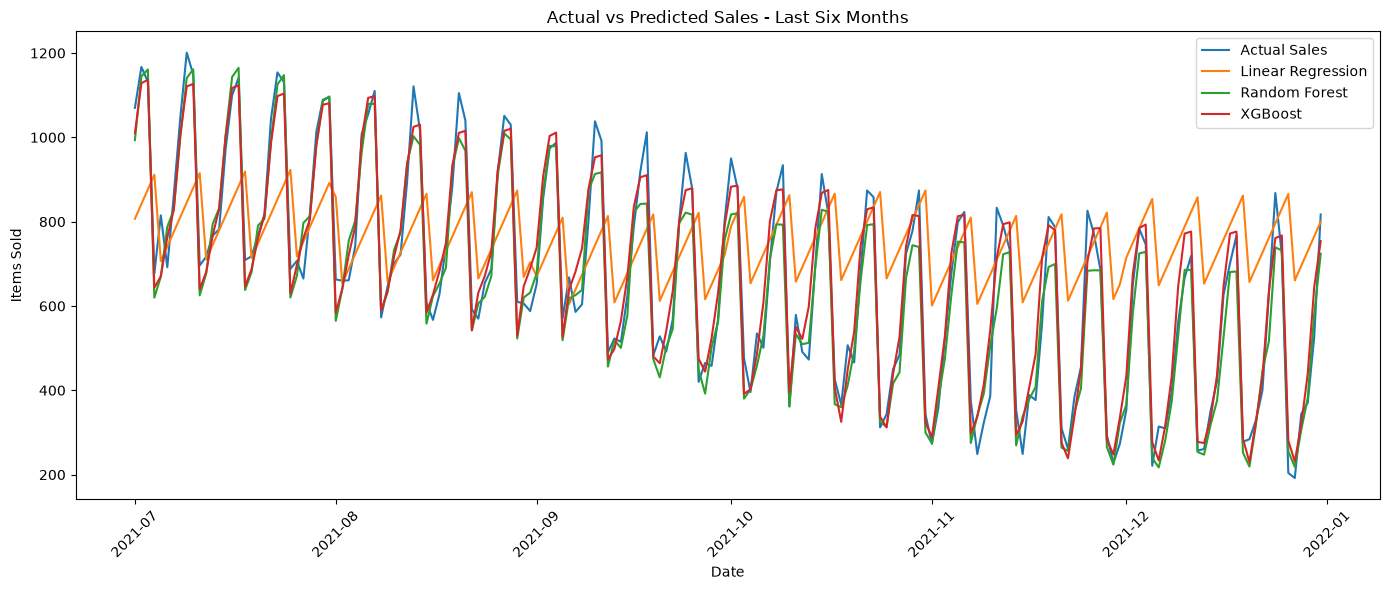

In [152]:
# ============================================================
# CELL 15 - TEST PERIOD PREDICTIONS
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    test_results["date"],
    test_results["sales"],
    label="Actual Sales"
)

plt.plot(
    test_results["date"],
    test_results["Linear Regression"],
    label="Linear Regression"
)

plt.plot(
    test_results["date"],
    test_results["Random Forest"],
    label="Random Forest"
)

plt.plot(
    test_results["date"],
    test_results["XGBoost"],
    label="XGBoost"
)

plt.title("Actual vs Predicted Sales - Last Six Months")
plt.xlabel("Date")
plt.ylabel("Items Sold")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [153]:
# ============================================================
# CELL 16 - PREPARE FULL DATA FOR FINAL MODEL
# ============================================================

X_full = daily_sales_ml[features]
y_full = daily_sales_ml["sales"]

print("Full training dataset:", X_full.shape)

Full training dataset: (1096, 6)


In [154]:
# ============================================================
# CELL 17 - TRAIN BEST MODEL ON FULL DATA
# ============================================================

if best_model_name == "Linear Regression":
    
    final_model = LinearRegression()
    
elif best_model_name == "Random Forest":
    
    final_model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
    
elif best_model_name == "XGBoost":
    
    final_model = XGBRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        objective="reg:squarederror",
        n_jobs=-1
    )

final_model.fit(X_full, y_full)

print(best_model_name, "trained on the complete historical dataset.")

XGBoost trained on the complete historical dataset.


In [155]:
# ============================================================
# CELL 18 - CREATE NEXT YEAR DATES
# ============================================================

forecast_start_date = max_date + pd.Timedelta(days=1)

forecast_dates = pd.date_range(
    start=forecast_start_date,
    periods=365,
    freq="D"
)

forecast_data = pd.DataFrame({
    "date": forecast_dates
})

display(forecast_data.head())
display(forecast_data.tail())

,date
0,2022-01-01
1,2022-01-02
2,2022-01-03
3,2022-01-04
4,2022-01-05


,date
360,2022-12-27
361,2022-12-28
362,2022-12-29
363,2022-12-30
364,2022-12-31


In [156]:
# ============================================================
# CELL 19 - CREATE FORECAST FEATURES
# ============================================================

forecast_data["day_of_week"] = forecast_data["date"].dt.dayofweek
forecast_data["quarter"] = forecast_data["date"].dt.quarter
forecast_data["month"] = forecast_data["date"].dt.month
forecast_data["year"] = forecast_data["date"].dt.year
forecast_data["day_of_month"] = forecast_data["date"].dt.day
forecast_data["day_of_year"] = forecast_data["date"].dt.dayofyear

X_forecast = forecast_data[features]

display(forecast_data.head())

,date,day_of_week,quarter,month,year,day_of_month,day_of_year
0,2022-01-01,5,1,1,2022,1,1
1,2022-01-02,6,1,1,2022,2,2
2,2022-01-03,0,1,1,2022,3,3
3,2022-01-04,1,1,1,2022,4,4
4,2022-01-05,2,1,1,2022,5,5


In [157]:
# ============================================================
# CELL 20 - GENERATE FORECAST
# ============================================================

forecast_predictions = final_model.predict(
    X_forecast
)

forecast_data["forecasted_sales"] = forecast_predictions

# Sales cannot be negative
forecast_data["forecasted_sales"] = (
    forecast_data["forecasted_sales"].clip(lower=0)
)

display(forecast_data.head(10))

,date,day_of_week,quarter,month,year,day_of_month,day_of_year,forecasted_sales
0,2022-01-01,5,1,1,2022,1,1,744.325623
1,2022-01-02,6,1,1,2022,2,2,318.020569
2,2022-01-03,0,1,1,2022,3,3,250.982971
3,2022-01-04,1,1,1,2022,4,4,323.989777
4,2022-01-05,2,1,1,2022,5,5,363.039185
5,2022-01-06,3,1,1,2022,6,6,540.324707
6,2022-01-07,4,1,1,2022,7,7,696.350891
7,2022-01-08,5,1,1,2022,8,8,696.350891
8,2022-01-09,6,1,1,2022,9,9,267.440308
9,2022-01-10,0,1,1,2022,10,10,237.539413


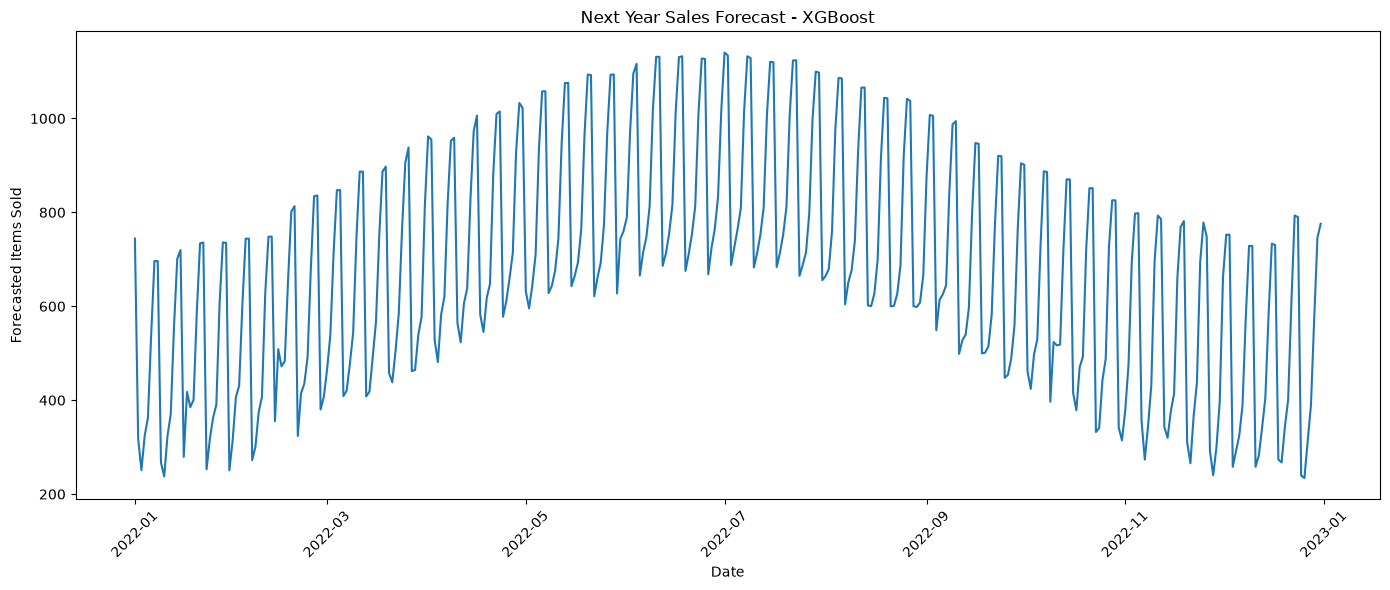

In [158]:
# ============================================================
# CELL 21 - NEXT YEAR SALES FORECAST
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    forecast_data["date"],
    forecast_data["forecasted_sales"]
)

plt.title(
    "Next Year Sales Forecast - " + best_model_name
)

plt.xlabel("Date")
plt.ylabel("Forecasted Items Sold")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [159]:
# ============================================================
# CELL 22 - MONTHLY FORECAST SUMMARY
# ============================================================

forecast_data["month"] = forecast_data["date"].dt.month
forecast_data["month_name"] = forecast_data["date"].dt.month_name()

monthly_forecast = (
    forecast_data
    .groupby(["month", "month_name"])["forecasted_sales"]
    .sum()
    .reset_index()
    .sort_values("month")
)

display(monthly_forecast)

,month,month_name,forecasted_sales
0,1,January,14615.300781
1,2,February,15299.129883
2,3,March,19655.595703
3,4,April,22842.728516
4,5,May,25373.720703
5,6,June,26668.535156
6,7,July,27674.894531
7,8,August,24503.515625
8,9,September,21334.123047
9,10,October,18547.835938


In [161]:
# ============================================================
# CELL 23 - FINAL FORECAST SUMMARY
# ============================================================

print("=" * 70)
print("MACHINE LEARNING FORECASTING SUMMARY")
print("=" * 70)

print("\nTest period:")
print(test_data["date"].min(), "to", test_data["date"].max())

print("\nModel RMSE:")
display(model_comparison)

print("\nBest-performing model:")
print(best_model_name)

print("\nBest RMSE:")
print(best_rmse)

print("\nForecast period:")
print(
    forecast_data["date"].min(),
    "to",
    forecast_data["date"].max()
)

print("\nTotal forecasted sales for next year:")
print(
    round(
        forecast_data["forecasted_sales"].sum(),
        2
    )
)

print("\nAverage forecasted daily sales:")
print(
    round(
        forecast_data["forecasted_sales"].mean(),
        2
    )
)

MACHINE LEARNING FORECASTING SUMMARY

Test period:
2021-07-01 00:00:00 to 2021-12-31 00:00:00

Model RMSE:


,Model,RMSE
0,XGBoost,56.966814
1,Random Forest,62.541335
2,Linear Regression,244.198704



Best-performing model:
XGBoost

Best RMSE:
56.96681409102794

Forecast period:
2022-01-01 00:00:00 to 2022-12-31 00:00:00

Total forecasted sales for next year:
247375.9

Average forecasted daily sales:
677.74


In [162]:
# ============================================================
# CELL 24 - SAVE FINAL MODEL
# ============================================================

import os
import joblib

# Create models directory
os.makedirs("models", exist_ok=True)

# Save the final trained model
model_path = "models/xgboost_sales_forecasting_model.pkl"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Model path:", model_path)

Model saved successfully!
Model path: models/xgboost_sales_forecasting_model.pkl


In [163]:
# ============================================================
# CELL 25 - SAVE MODEL FEATURES
# ============================================================

features_path = "models/xgboost_features.pkl"

joblib.dump(features, features_path)

print("Feature list saved successfully!")
print("Feature path:", features_path)
print("\nFeatures used:")
print(features)

Feature list saved successfully!
Feature path: models/xgboost_features.pkl

Features used:
['day_of_week', 'quarter', 'month', 'year', 'day_of_month', 'day_of_year']


In [164]:
# ============================================================
# CELL 26 - VERIFY SAVED MODEL
# ============================================================

loaded_model = joblib.load(model_path)

print("Saved model loaded successfully!")
print("Model type:", type(loaded_model).__name__)

Saved model loaded successfully!
Model type: XGBRegressor


In [165]:
# ============================================================
# CELL 27 - VERIFY MODEL PREDICTION
# ============================================================

# Test prediction using the loaded model
test_prediction = loaded_model.predict(
    X_test.head(5)
)

print("Sample predictions from saved model:")
print(test_prediction)

Sample predictions from saved model:
[1033.7179 1138.0159 1133.8086  687.9002  736.321 ]
